<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/EX11_Clustering_GRB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **GAMMA RAY BURST**

**gamma-ray bursts (GRBs)** are extremely energetic events occurring in distant galaxies that represent the brightest and most powerful class of explosion in the Universe.
hese extreme electromagnetic emissions are second only to the Big Bang as the most energetic and luminous phenomena known.
Gamma-ray bursts can last from a few milliseconds to several hours.

**CLASSIFICATION**

Plots of the distribution of the observed duration for a large number of gamma-ray bursts show a clear bimodality, suggesting the existence of two separate populations:

*  "Short" population with an average duration of about 0.3 seconds

*  "Long" population with an average duration of about 30 seconds.

Both distributions are very broad with a significant overlap region in which the identity of a given event is not clear from duration alone.

 Additional classes beyond this two-tiered system have been proposed on both observational and theoretical grounds.

[wikipedia](https://en.wikipedia.org/wiki/Gamma-ray_burst)

#  **CLUSTERING**

In [29]:
import requests
import numpy as np
from matplotlib import pylab as plt

# Download file
r = requests.get('https://user-web.icecube.wisc.edu/~grbweb_public/Summary_table.txt')
with open("Summary_table.txt", 'wb') as f:
    f.write(r.content)

# Read content
data = np.loadtxt("Summary_table.txt", dtype='str',unpack='True')

# Read headers
with open("Summary_table.txt",'r') as f:
    names = np.array([n.strip().replace(" ","_") for n in f.readlines()[1].replace("#","").replace("\n","").lstrip().split('    ') if n.strip()!=''])

/tmp/ipykernel_590/3528598067.py:11: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  data = np.loadtxt("Summary_table.txt", dtype='str',unpack='True')


*   **PRE-PROCESSING**



In [92]:
from sklearn.preprocessing import StandardScaler

grb=dict(zip(names,data))
for lab in ['T90',"redshift",'T90_error']:
    grb[lab] = np.array(grb[lab],dtype='float')
#filtering the data 4 1d no mask togheter to preserve n of Data
grbT90=np.log(grb['T90'][grb['T90'] > 0])
grbredshift=np.log(grb['redshift'][grb['redshift'] > 0])

#preprocessing the data
scaler = StandardScaler()
T90_raw = grbT90.reshape(-1,1)
redshift_raw= grbredshift.reshape(-1,1)
T90 =  scaler.fit_transform(T90_raw)
redshift = scaler.fit_transform(redshift_raw)



**1-D SUBPLOTS ANALYSIS**




*  KERNAL DENSITY ESTIMATION

In [31]:
#finding optimal bandwidth with cross validation
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KernelDensity


bwrange = np.linspace(0.10,0.5, 10)
K = 5 # Do 5-fold cross validation
grid = GridSearchCV(KernelDensity(), {'bandwidth': bwrange}, cv= K) # Try each bandwidth with K-folds

#T90
grid.fit(T90.flatten()[:, None])
h_opt_T90 = grid.best_params_['bandwidth']

#redshift
grid.fit(redshift.flatten()[:, None])
h_opt_redshift = grid.best_params_['bandwidth']

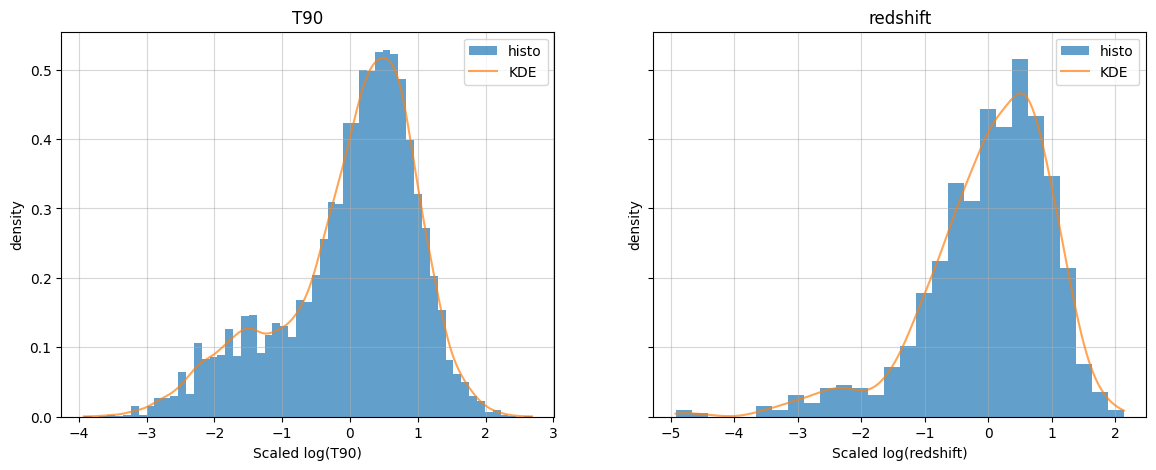

In [86]:
def kde_sklearn(data, xgrid, bandwidth):
    kde_skl = KernelDensity(bandwidth=bandwidth)
    kde_skl.fit(data[:, np.newaxis])
    log_pdf = kde_skl.score_samples(xgrid[:, np.newaxis])
    return np.exp(log_pdf)

def plot_kde_kmeans(ax, data_scaled, feature_name, bandwidth, centers):
    # data flattening data for plotting
    data_1d = data_scaled.flatten()
    xgrid = np.linspace(np.min(data_1d), np.max(data_1d), len(data_1d))

    #  KDE
    pdf = kde_sklearn(data_1d, xgrid, bandwidth)

    # Plotting
    ax.grid(alpha=0.5)
    ax.hist(data_1d, bins='fd', alpha=0.7, density=True, label='histo')
    ax.plot(xgrid, pdf, alpha=0.7, label='KDE')

    # centers
    for i, center in enumerate(centers):
        ax.axvline(x=center[0], label=f'K-MEANS centroid {i+1}', color='red', alpha=0.6, linestyle='--')
    sorted_centers = np.sort(centers)

    #bonds
    for i in range(len(sorted_centers) - 1):
        bound = 0.5 * (sorted_centers[i] + sorted_centers[i+1])
        ax.axvline(x=bound, label=f'separation ', color='green', alpha=0.6, linestyle=':')
    ax.set_title(f'{feature_name}')
    ax.set_xlabel(f'Scaled log({feature_name})')
    ax.set_ylabel("density")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)


plot_kde_kmeans(axes[0], T90, 'T90', h_opt_T90, [])
plot_kde_kmeans(axes[1], redshift, 'redshift', h_opt_redshift,[] )

plt.show()


*  **CLUSTERING**

*  K-MEANS

In [33]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def siluette(n_clusters_grid,data):
  siluette_arr=[]
  for i in (n_clusters_grid):
    clf = KMeans(n_clusters=i,n_init='auto')
    clusters_labels=clf.fit_predict(data)
    score = silhouette_score(data, clusters_labels)
    siluette_arr.append(score)
  best_n_clusters=n_clusters_grid[np.argmax(siluette_arr)]
  return siluette_arr,best_n_clusters

### Silhouette Analysis

To choose $K$ in a data-driven way, we use the **Silhouette Coefficient**. For each sample $i$ assigned to cluster $C_I$, we define:
* **Cohesion ($a_i$):** the mean intra-cluster distance between $i$ and all other points in the same cluster $C_I$:
  $$a(i) = \frac{1}{|C_I| - 1} \sum_{j \in C_I, \, j \neq i} d(x_i, x_j)$$
* **Separation ($b_i$):** the mean nearest-cluster distance, i.e., the minimum average distance from $i$ to all points in any other cluster $C_J \neq C_I$:
  $$b(i) = \min_{J \neq I} \frac{1}{|C_J|} \sum_{j \in C_J} d(x_i, x_j)$$

The silhouette score for sample $i$ is then:
$$s(i) = \frac{b(i) - a(i)}{\max\big(a(i), b(i)\big)} \in [-1, 1]$$

* $s(i) \approx +1$: the sample is well inside its own cluster and far from neighboring clusters (dense, well-separated clustering).
* $s(i) \approx 0$: the sample lies close to the decision boundary between two clusters.
* $s(i) < 0$: the sample is likely assigned to the wrong cluster.

We compute the global mean silhouette score $\bar{s}(K) = \frac{1}{N}\sum_{i=1}^N s(i)$ across a range of candidate values ($K \ge 2$) and select the $K$ that **maximizes** $\bar{s}(K)$. Note that, since it relies on pairwise Euclidean distances, this metric assumes convex, roughly isotropic clusters and cannot evaluate the $K=1$ hypothesis.

In [34]:
#siluette test
n_clusters_grid=np.linspace(2, 10, 10, dtype=int)

siluette_T90,n_clusters_T90= siluette(n_clusters_grid,T90)
siluette_redshift,n_clusters_redshift=siluette(n_clusters_grid,redshift)

print('---------SILHOUETTE TEST----------')
print(f'The optimal n of clusters for T_90 is {n_clusters_T90:.4f}')
print(f'The optimal n of clusters for redshift is {n_clusters_redshift:.4f}')


#plotting
#plt.plot(n_clusters_grid,siluette_T90,label='T90')
#plt.plot(n_clusters_grid,siluette_T90,label='redshift',linestyle='--')

#plt.title('SILOUETTE TEST')
#plt.grid(alpha=0.7)
#plt.legend();


---------SILHOUETTE TEST----------
The optimal n of clusters for T_90 is 2.0000
The optimal n of clusters for redshift is 2.0000


**KMeans clustering** with optimal parameters

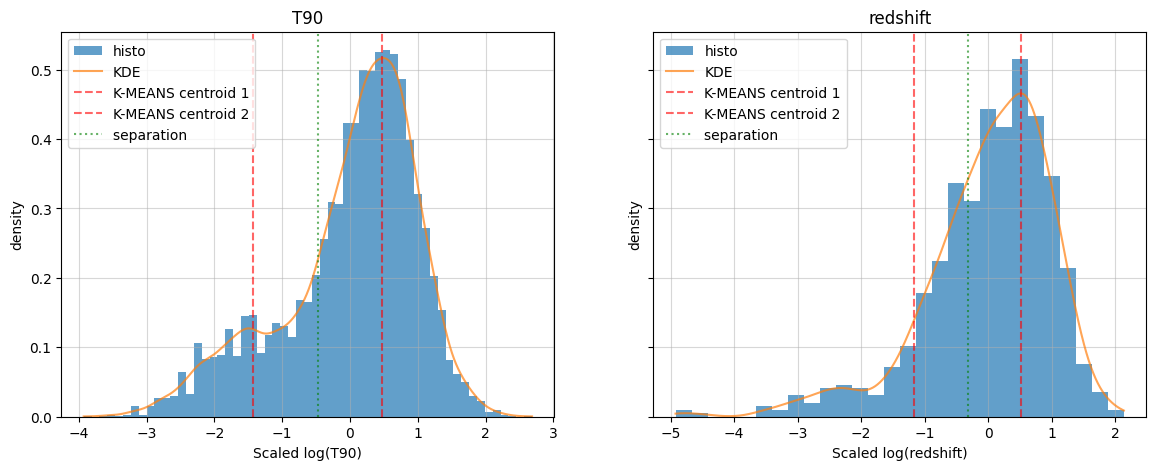

In [35]:
#t90
clf_T90 = KMeans(n_clusters=n_clusters_T90,n_init='auto')
clf_T90.fit(T90)
centers_T90 = clf_T90.cluster_centers_ #location of the clusters
#labels_T90 = clf_T90.predict(T90) #labels for each of the points #

#redshift
clf_red = KMeans(n_clusters=n_clusters_redshift,n_init='auto')
clf_red.fit(redshift)
centers_red = clf_red.cluster_centers_ #location of the clusters
#labels_red = clf_red.predict(redshift) #labels for each of the points


#plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

plot_kde_kmeans(axes[0], T90, 'T90', h_opt_T90, centers_T90) #T90
plot_kde_kmeans(axes[1], redshift, 'redshift', h_opt_redshift,centers_red ) #red

plt.show()




*   **MEAN SHIFT CLUSTERING**



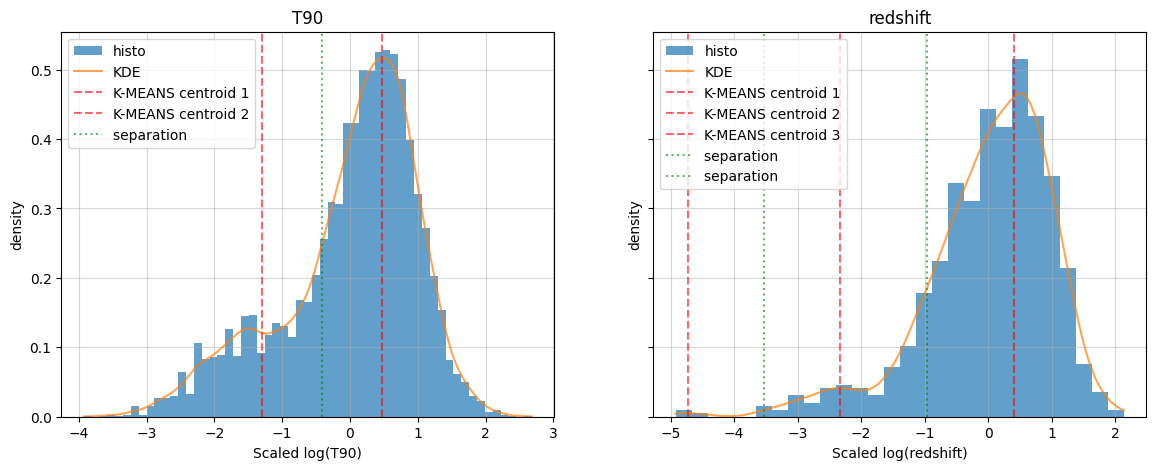

In [98]:
from sklearn.cluster import MeanShift
from sklearn.cluster import estimate_bandwidth
#T90
def MS(data):
  band = estimate_bandwidth(data,quantile=0.2) #extimating best bandwidth
  ms = MeanShift(bandwidth=band,
                 bin_seeding=True,
                cluster_all=False   #tring to make it more robust
               )
  ms.fit(data)
  labels = np.unique(ms.labels_)

  cluster_centers = ms.cluster_centers_

  return labels,cluster_centers

labels_MS_T90,MS_centers_T90 = MS(T90)
labels_MS_red,MS_centers_red = MS(redshift)


#plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

plot_kde_kmeans(axes[0], T90, 'T90', h_opt_T90, MS_centers_T90)
plot_kde_kmeans(axes[1], redshift, 'redshift', h_opt_redshift,MS_centers_red )

plt.show()




* **Gaussian mixture**



In [37]:

import scipy as sp
from sklearn.mixture import GaussianMixture as gmix
'''
def Ks_gauss (data,n_comp):
  gm = gmix(n_components=n_comp,random_state=42) #2 from previous guess
  gm.fit(data)

  gmm_cdf = lambda x: np.sum([ #computing cdf for kstest
    w * sp.stats.norm.cdf(x, loc=m, scale=np.sqrt(c))
    for w, m, c in zip(gm.weights_, gm.means_.ravel(), gm.covariances_.ravel())
  ], axis=0)

  ks_stat, p_value = sp.stats.kstest(data,gmm_cdf)
  return p_value


p_value_t90=Ks_gauss(T90,2)
p_value_red=Ks_gauss(redshift,2)
print(f'GaussianMixture p_values for T90 is: {p_value_t90[0]:.4f}')
print(f'GaussianMixture p_values for redshift is: {p_value_red[0]:.4f}')
'''

GaussianMixture p_values for T90 is: 0.6066
GaussianMixture p_values for redshift is: 0.3639


*  number of modes extimation


In [38]:
def n_comp_gausMix (data):
  n_components = np.arange(1, 7)
  bic, aic = [], []
  for k in n_components:
    gm = gmix(k,random_state=0).fit(data)
    bic.append(gm.bic(data)); aic.append(gm.aic(data))
  bic, aic = np.array(bic), np.array(aic)
  n_bic, n_aic = n_components[bic.argmin()], n_components[aic.argmin()]
  return n_bic, n_aic

Aic_t90,Bic_t90=n_comp_gausMix(T90)
Aic_red,Bic_red=n_comp_gausMix(redshift)
print('------T90------')
print(f'optimal number of modes for T90 using  AIC is: {Aic_t90:.4f} and using BIC is:{Bic_t90:.4f}')
print('------Redshift------')
print(f'optimal number of modes for redshift using  AIC is: {Aic_red:.4f} and using BIC is:{Bic_red:.4f}')


------T90------
optimal number of modes for T90 using  AIC is: 2.0000 and using BIC is:2.0000
------Redshift------
optimal number of modes for redshift using  AIC is: 3.0000 and using BIC is:3.0000


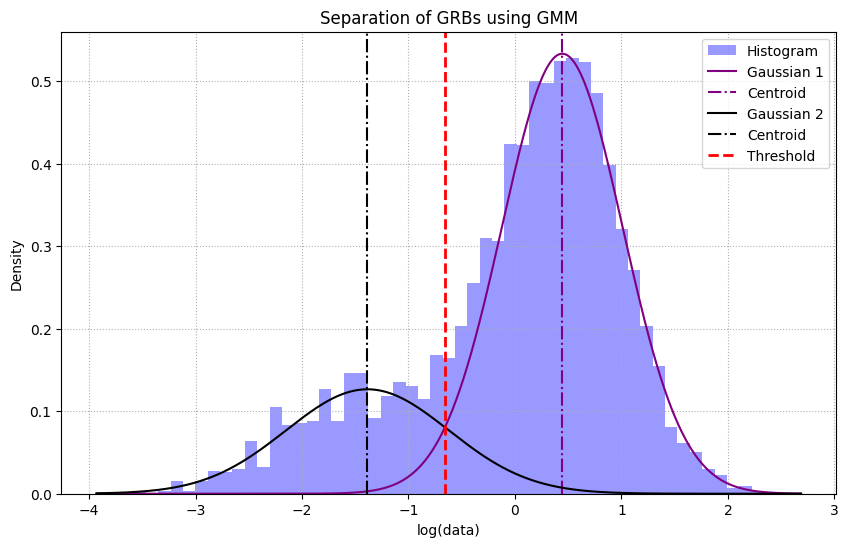

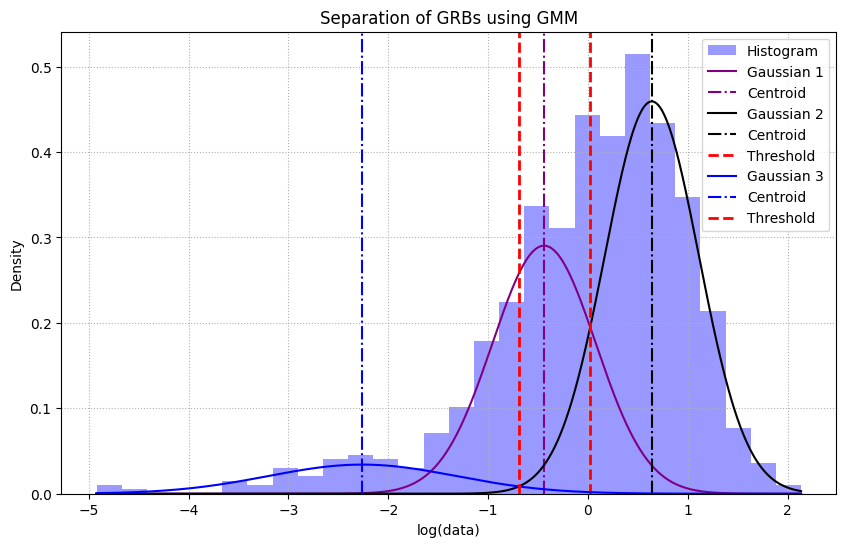

In [80]:
from scipy.optimize import fsolve
import numpy as np
import matplotlib.pyplot as plt

def plotgm(data, n_clusters):
  gmm = gmix(n_components=n_clusters, random_state=42)
  gmm.fit(data)
  labels = gmm.predict(data)

  # Punti per disegnare le gaussiane
  xgrid = np.linspace(data.min(), data.max(), 1000).reshape(-1,1)

  # Calcolo delle singole gaussiane dal GMM
  means = gmm.means_.flatten()
  stds = np.sqrt(gmm.covariances_.flatten())
  weights = gmm.weights_

  plt.figure(figsize=(10,6))
  colors = ["purple", "black", "blue"]

  # Histogram
  plt.hist(data, bins="fd", color='blue', density=True, alpha=0.4, edgecolor='none', label='Histogram')

  centroid=[]
  # Gaussians
  for i in range(n_clusters):
    mean = means[i]
    std = stds[i]
    weight = weights[i]
    centroid.append(mean)

    gaussian = weight * (1/(std*np.sqrt(2*np.pi))) * np.exp(-0.5*((xgrid.flatten()-mean)/std)**2)
    plt.plot(xgrid, gaussian, color=colors[i], label=f'Gaussian {i+1}')
    plt.axvline(mean, color=colors[i], linestyle='-.', label=f'Centroid')

    # Intersection point
    def gaussian_pdf(x, mean, std, weight):
      return weight * (1/(std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mean)/std)**2)

    def diff(x, idx):
      if idx > 1:
        return gaussian_pdf(x, means[idx-1], stds[idx-1], weights[idx-1]) - gaussian_pdf(x, means[idx], stds[idx], weights[idx])
      else:
        return gaussian_pdf(x, means[0], stds[0], weights[0]) - gaussian_pdf(x, means[1], stds[1], weights[1])

    if i > 0:
      if i > 1:
        x_intersection = fsolve(diff, x0=(means[i-1] + means[i]) / 2, args=(i,))[0]
      else:
        x_intersection = fsolve(diff, x0=(means[0] + means[1]) / 2, args=(i,))[0]
      plt.axvline(x_intersection, color='red', linestyle='--', linewidth=2, label=f'Threshold ')

  # Labels
  plt.xlabel(f'log(data)')
  plt.ylabel('Density')
  plt.title('Separation of GRBs using GMM')
  plt.legend()
  plt.grid(True, linestyle=":")

  return centroid


centroid_gmm_T90=plotgm(T90, int(Aic_t90))
centroid_gmm_red=plotgm(redshift, int(Aic_red))
plt.show()


Both clustering algorithms reveal clear multimodality across both plots.

However, the redshift feature exhibits higher sensitivity to outliers: specifically, both Mean-Shift and the Gaussian Mixture Model (GMM) identify 3 clusters (`n_clusters = 3` for Mean-Shift and `n_components = 3` for GMM).

Where my guess is that the third component is likely driven by the extended tail / outlier population rather than a distinct physical mode.


*    **OUTLIERS**

**DB-SCAN**:
Given a set of points in some space, it groups together points that are closely packed (points with many nearby neighbors), and marks as outliers points that lie alone in low-density regions (those whose nearest neighbors are too far away).

The algorithm is governed by two hyperparameters:
* **$\epsilon$ (`eps`):** the radius defining the local neighborhood around each point, $N_\epsilon(x_i) = \{x_j \in X \mid d(x_i, x_j) \le \epsilon\}$.
* **$\text{MinPts}$ (`min_samples`):** the minimum number of points required within $N_\epsilon(x_i)$ (including $x_i$ itself) to form a dense region.

In [79]:
from sklearn.cluster import DBSCAN as db

def DB(data):
  dbscan = db(eps=0.3)
  labels = dbscan.fit_predict(data)
  inliers = data[labels != -1]
  return inliers

inliers_T90= DB(T90)
inliers_red = DB(redshift)


#BDSCAN here only used for computing the inliers but is a clustering alghoritm itself!

*  **Mean shift without outliers**




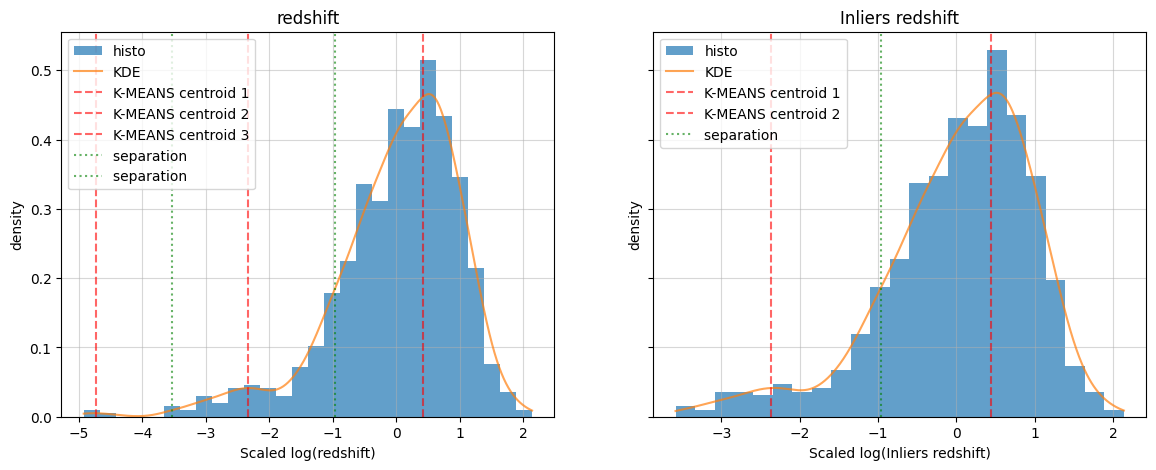

In [99]:

#labels_MS_T90_in,MS_centers_T90_in = MS(inliers_T90)
labels_MS_red_in,MS_centers_red_in = MS(inliers_red)

#plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

plot_kde_kmeans(axes[0], redshift, 'redshift', h_opt_redshift,MS_centers_red )
plot_kde_kmeans(axes[1], inliers_red, 'Inliers redshift', h_opt_redshift,MS_centers_red_in )

plt.show()




 *  **GAUSSIAN MIXTURE WITHOUT OUTLIERS**


In [100]:
Aic_t90_in,Bic_t90_in=n_comp_gausMix(inliers_T90)
Aic_red_in,Bic_red_in=n_comp_gausMix(inliers_red)
print('------T90------')
print(f'optimal number of modes for T90 without outliers: \nusing  AIC is: {Aic_t90_in:.4f} and using BIC is:{Bic_t90_in:.4f}')
print('------Redshift------')
print(f'optimal number of modes for redshift without outliers: \nusing  AIC is: {Aic_red_in:.4f} and using BIC is:{Bic_red_in:.4f}')


#plotgm(inliers_red, int(Aic_red_in))
#plt.show()


------T90------
optimal number of modes for T90 without outliers: 
using  AIC is: 2.0000 and using BIC is:2.0000
------Redshift------
optimal number of modes for redshift without outliers: 
using  AIC is: 3.0000 and using BIC is:3.0000


#  **2-D clustering**



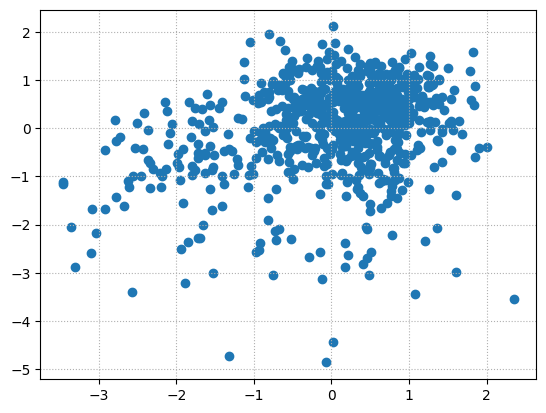

In [101]:
for lab in ['T90',"redshift"]:
    grb[lab] = np.array(grb[lab],dtype='float')
#filtering the data 4 1d no mask togheter to preserve n of Data
mask= (grb['T90'] > 0) & (grb['redshift'] >0)
T90_raw_2d=np.log(grb['T90'][mask])
redshift_raw_2d=np.log(grb['redshift'][mask])

raw_2d=np.column_stack((T90_raw_2d,redshift_raw_2d))

#preprocessing the data
data_2d = scaler.fit_transform(raw_2d)

plt.grid(linestyle = ':')
plt.scatter(data_2d[:,0],data_2d[:,1]);

K-MEAN

In [102]:
#optimal n_clusters
siluette_2d,n_clusters_2d= siluette(n_clusters_grid,data_2d)

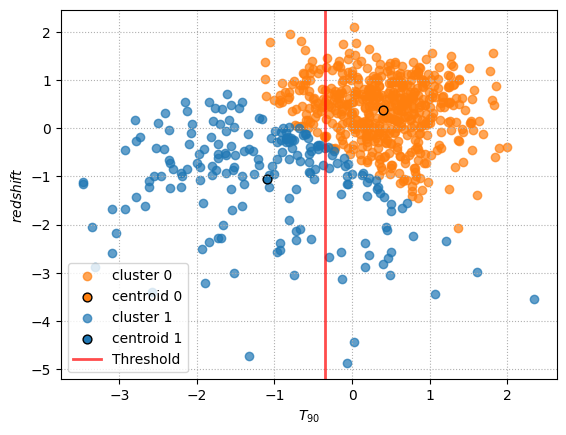


 the threshold is at: 27.91013931117337 s
 the centroids are at : 3.1482531645827825 s and at 52.67202545776396


In [116]:
def Kmean_2d(data,n_clusters):
  clf = KMeans(n_clusters=n_clusters_2d,n_init='auto')
  clf.fit(data_2d)
  centers = clf.cluster_centers_ #location of the clusters
  labels = clf.predict(data_2d) #labels for each of the points
  bound= (centers[0, 0] + centers[1, 0]) / 2.0
  colors = ['C1', 'C0']
  for ii in range(n_clusters_2d):
    plt.scatter(data_2d[labels==ii,0], data_2d[labels==ii,1],
                color=colors[ii],alpha=0.7,label=f'cluster {int(ii)}')
    plt.scatter(centers[ ii,0], centers[ii, 1],
          s=40, c=colors[ii], edgecolors='k',label=f'centroid {int(ii)}')

  plt.axvline(x=bound, color='red', linestyle='-', linewidth=2,
            label=f'Threshold',alpha=0.7)
  plt.grid(linestyle = ':')
  plt.legend()
  plt.xlabel(r'$T_{90}$')
  plt.ylabel(r'$redshift$')
  plt.show()

  #rescaling the bound
  centers_log = scaler.inverse_transform(centers)
  centers_real = np.exp(centers_log)
  bound_real = (centers_real[0, 0] + centers_real[1, 0]) / 2.0

  return bound_real,centers_real
threshold_2d, centers_2d =Kmean_2d(data_2d,n_clusters_2d)
print(f'\n the threshold is at: {threshold_2d} s')
print(f' the centroids are at : {centers_2d[1,0]} s and at {centers_2d[0,0]}')



WITHOUT OUTLIERS

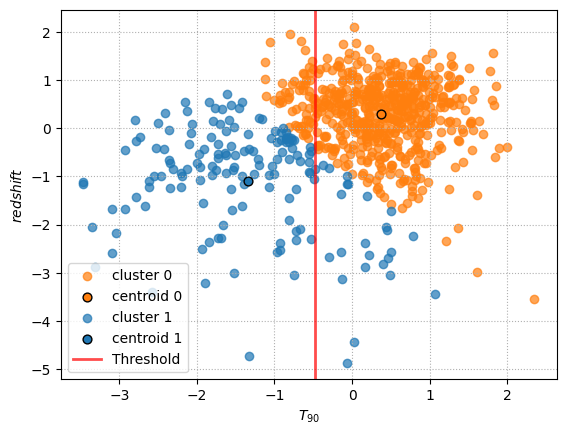


 the threshold is at: 26.355586731476222 s
 the centroids are at : 1.9690087131111227 s and at 50.74216474984132 s


In [123]:
#removing outliers
inliers_2d=DB(data_2d)
#siluette
siluette_2d,n_clusters_2d_in= siluette(n_clusters_grid,inliers_2d)

threshold_2d_in, centers_2d_in =Kmean_2d(inliers_2d,n_clusters_2d_in)
print(f'\n the threshold is at: {threshold_2d_in} s')
print(f' the centroids are at : {centers_2d_in[1,0]} s and at {centers_2d_in[0,0]} s')


# **ERROR ESTIMATION**

GRBs with a measured T90 error: 7021 of 8155 valid T90 (total catalog: 9406)
typical (median) error: about 12% of the T90 value


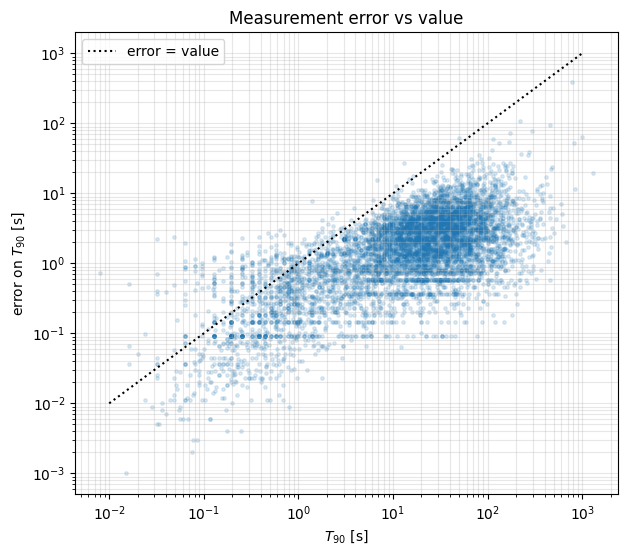

In [128]:
valid_T90 = np.isfinite(grb['T90']) & (grb['T90'] > 0)
he = valid_T90 & np.isfinite(grb['T90_error']) & (grb['T90_error'] > 0)

rel_err = grb['T90_error'][he] / grb['T90'][he]

print(f"GRBs with a measured T90 error: {he.sum()} of {valid_T90.sum()} valid T90 (total catalog: {len(grb['T90'])})")
print(f"typical (median) error: about {np.median(rel_err)*100:.0f}% of the T90 value")
plt.figure(figsize=(7, 6))
plt.scatter(grb['T90'][he], grb['T90_error'][he], s=6, alpha=0.15, color='C0')
plt.plot([1e-2, 1e3], [1e-2, 1e3], 'k:', label='error = value')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$T_{90}$ [s]')
plt.ylabel(r'error on $T_{90}$ [s]')
plt.title('Measurement error vs value')
plt.legend()
plt.grid(alpha=0.3, which='both')
plt.show()





We can see that most of the measurement errors lie below the dashed line, with a median relative error of about $10\%$ ($\sigma_{\log_{10} T_{90}} \approx 0.043\,\text{dex}$). Since the cluster centroids are located at $3.15\,\text{s}$ and $52.67\,\text{s}$ (separated by $\sim 1.22\,\text{dex}$), the measurement uncertainties are nearly $30$ times smaller than the separation between the two populations and can be safely neglected.